# DIT5411 — Traditional Chinese Handwriting Recognition

This notebook compares an MLP, a basic CNN, and a deep CNN for recognition of 13,065 traditional Chinese character classes. Steps 1–18 cover data preparation, augmentation, training, and evaluation.

## Part A — Environment and dataset preparation


In [1]:
# Step 1 — Imports, paths, experiment settings and GPU verification
from pathlib import Path
import gc
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

SEED = 42
IMG_SIZE = 64
BATCH_SIZE = 32  # Lower to 16 if you encounter GPU out-of-memory errors.
EPOCHS = 8
INITIAL_LEARNING_RATE = 3e-4
MIN_LEARNING_RATE = 1e-5
NUM_CLASSES = 13065
SAMPLES_PER_CLASS = 200
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp"}

PROJECT_DIR = Path.home() / "DIT5411"
DATA_DIR = PROJECT_DIR / "dataset" / "cleaned_data"
RESULT_DIR = PROJECT_DIR / "results_diagnostic_v4"
MODEL_DIR = RESULT_DIR / "models"
BACKUP_DIR = RESULT_DIR / "backups"
for directory in (RESULT_DIR, MODEL_DIR, BACKUP_DIR):
    directory.mkdir(parents=True, exist_ok=True)

assert DATA_DIR.is_dir(), f"Dataset directory not found: {DATA_DIR}"
tf.keras.utils.set_random_seed(SEED)
gpus = tf.config.list_physical_devices("GPU")
assert gpus, "No TensorFlow GPU detected. Complete WSL2/CUDA setup first."
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

print("TensorFlow version:", tf.__version__)
print("Detected GPUs:", gpus)
print("Dataset path:", DATA_DIR)
print("Output path:", RESULT_DIR)


2026-11-19 03:17:52.192694: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-19 03:17:52.295433: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-11-19 03:17:53.547618: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow version: 2.20.0
Detected GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Dataset path: /home/lauti/DIT5411/dataset/cleaned_data
Output path: /home/lauti/DIT5411/results_diagnostic_v4


In [2]:
# Step 2 — Verify the complete dataset and number of images per class
class_folders = sorted(
    (path for path in DATA_DIR.iterdir() if path.is_dir()),
    key=lambda path: path.name
)
assert len(class_folders) == NUM_CLASSES, (
    f"Expected {NUM_CLASSES} classes, found {len(class_folders)}"
)

# Cache paths to avoid rescanning 684,677 files in Step 3.
images_by_class = []
for folder in class_folders:
    images = sorted(
        (path for path in folder.iterdir()
         if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS),
        key=lambda path: path.name
    )
    if len(images) < 2:
        raise ValueError(f"Insufficient images in class: {folder.name}")
    images_by_class.append(images)

image_counts = np.array([len(images) for images in images_by_class])
assert int(image_counts.sum()) == 684677, "Unexpected image count. Verify the full dataset."

print("Total classes:", len(class_folders))
print("Total images:", int(image_counts.sum()))
print("Minimum images per class:", int(image_counts.min()))
print("Maximum images per class:", int(image_counts.max()))
print("Classes with fewer than 40 images:", int(np.sum(image_counts < 40)))
print("Classes with 40 or fewer images:", int(np.sum(image_counts <= 40)))


Total classes: 13065
Total images: 684677
Minimum images per class: 16
Maximum images per class: 61
Classes with fewer than 40 images: 43
Classes with 40 or fewer images: 43


In [3]:
# Step 3 — Reproducible training/testing split and saved metadata
train_records = []
test_records = []
fallback_count = 0

for class_id, (folder, images) in enumerate(zip(class_folders, images_by_class)):
    count = len(images)
    split_point = min(40, count)
    fallback_count += int(count <= 40)

    for path in images[:split_point]:
        train_records.append((str(path.relative_to(DATA_DIR)), class_id, folder.name))
    for path in images[split_point:]:
        test_records.append((str(path.relative_to(DATA_DIR)), class_id, folder.name))

train_df = pd.DataFrame(train_records, columns=["filepath", "label", "character"])
test_df = pd.DataFrame(test_records, columns=["filepath", "label", "character"])
class_names = [folder.name for folder in class_folders]

assert len(train_df) + len(test_df) == 684677
assert train_df["label"].nunique() == NUM_CLASSES
assert set(train_df["filepath"]).isdisjoint(set(test_df["filepath"]))

train_df.to_csv(RESULT_DIR / "train.csv", index=False)
test_df.to_csv(RESULT_DIR / "test.csv", index=False)
(RESULT_DIR / "class_names.json").write_text(
    json.dumps(class_names, ensure_ascii=False, indent=2), encoding="utf-8"
)

print("Original training images:", len(train_df))
print("Independent testing images:", len(test_df))
print("Classes without held-out images:", fallback_count)
print("Training/testing split verified; no original image overlap.")


Original training images: 522127
Independent testing images: 162550
Classes without held-out images: 43
Training/testing split verified; no original image overlap.


## Part B — Data augmentation and TensorFlow dataset pipelines


In [4]:
# Step 4 — Make an augmentation plan: exactly 200 training samples per class
indices_by_class = train_df.groupby("label").indices
sample_count = NUM_CLASSES * SAMPLES_PER_CLASS
source_indices = np.empty(sample_count, dtype=np.int32)
plan_labels = np.repeat(np.arange(NUM_CLASSES, dtype=np.int32), SAMPLES_PER_CLASS)
augmentation_flags = np.empty(sample_count, dtype=np.bool_)

for class_id in range(NUM_CLASSES):
    indices = np.asarray(indices_by_class[class_id], dtype=np.int32)
    start = class_id * SAMPLES_PER_CLASS
    stop = start + SAMPLES_PER_CLASS
    source_indices[start:stop] = np.resize(indices, SAMPLES_PER_CLASS)
    augmentation_flags[start:stop] = np.arange(SAMPLES_PER_CLASS) >= len(indices)

assert np.array_equal(train_df["label"].to_numpy()[source_indices], plan_labels)
assert np.all(np.bincount(plan_labels, minlength=NUM_CLASSES) == 200)

# Shuffle all classes globally, avoiding class-ordered training batches.
order = np.random.default_rng(SEED).permutation(sample_count)
source_indices = source_indices[order]
plan_labels = plan_labels[order]
augmentation_flags = augmentation_flags[order]

print("Total planned training samples:", sample_count)
print("Unmodified training entries:", int((~augmentation_flags).sum()))
print("Augmented training entries:", int(augmentation_flags.sum()))
print("Samples per class:", SAMPLES_PER_CLASS)


Total planned training samples: 2613000
Unmodified training entries: 522127
Augmented training entries: 2090873
Samples per class: 200


In [5]:
# Step 5 — Image decoding, resizing and normalization
train_paths = tf.constant([str(DATA_DIR / p) for p in train_df["filepath"]])
test_paths = [str(DATA_DIR / p) for p in test_df["filepath"]]
test_labels = test_df["label"].to_numpy(dtype=np.int32)

def decode_and_preprocess(filepath):
    raw = tf.io.read_file(filepath)
    image = tf.io.decode_image(raw, channels=3, expand_animations=False)
    image.set_shape((None, None, 3))
    image = tf.image.rgb_to_grayscale(image)
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE), method="area")
    # Convert white background to zero and dark handwriting strokes to positive values.
    image = tf.cast(image, tf.float32) / 255.0
    return 1.0 - image

print("Preprocessing: 64x64 grayscale; white background inverted to 0 and strokes near 1.")


I0000 00:00:1795029522.006723    8752 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9513 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070 SUPER, pci bus id: 0000:01:00.0, compute capability: 8.9


Preprocessing: 64x64 grayscale; white background inverted to 0 and strokes near 1.


In [6]:
# Step 6 — Random rotation, shearing, zoom and translation (training only)
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(10 / 360, fill_mode="nearest"),
    tf.keras.layers.RandomShear(x_factor=0.08, fill_mode="nearest"),
    tf.keras.layers.RandomZoom(
        height_factor=(-0.08, 0.08),
        width_factor=(-0.08, 0.08),
        fill_mode="nearest"
    ),
    tf.keras.layers.RandomTranslation(
        height_factor=0.04, width_factor=0.04, fill_mode="nearest"
    ),
], name="training_augmentation")

# Horizontal/vertical flips are deliberately excluded.
def load_training_record(index, label, apply_aug):
    image = decode_and_preprocess(tf.gather(train_paths, index))
    return image, tf.cast(label, tf.int32), apply_aug

def augment_training_batch(images, labels, flags):
    transformed = augmentation(images, training=True)
    images = tf.where(flags[:, None, None, None], transformed, images)
    return images, labels

def load_testing_record(filepath, label):
    return decode_and_preprocess(filepath), tf.cast(label, tf.int32)

print("Training-only augmentation functions are ready.")


Training-only augmentation functions are ready.


In [7]:
# Step 7 — Build the streaming training and independent testing datasets
train_ds = tf.data.Dataset.from_tensor_slices(
    (source_indices, plan_labels, augmentation_flags)
)
train_ds = train_ds.shuffle(8192, seed=SEED, reshuffle_each_iteration=True)
train_ds = train_ds.map(load_training_record, num_parallel_calls=tf.data.AUTOTUNE)
train_ds = train_ds.batch(BATCH_SIZE)
train_ds = train_ds.map(augment_training_batch, num_parallel_calls=tf.data.AUTOTUNE)
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)

test_ds = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
test_ds = test_ds.map(load_testing_record, num_parallel_calls=tf.data.AUTOTUNE)
test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Training samples:", sample_count)
print("Training steps per epoch:", (sample_count + BATCH_SIZE - 1) // BATCH_SIZE)
print("Testing images:", len(test_df))
print("Both TensorFlow datasets are ready.")


Training samples: 2613000
Training steps per epoch: 81657
Testing images: 162550
Both TensorFlow datasets are ready.


2026-11-19 03:19:04.855354: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: CANCELLED: RecvAsync is cancelled.
	 [[{{node training_augmentation_1/random_rotation_1/Add/_18}}]] [type.googleapis.com/tensorflow.DerivedStatus='']
2026-11-19 03:19:04.855405: I tensorflow/core/framework/local_rendezvous.cc:426] Local rendezvous recv item cancelled. Key hash: 10880525372182868492
2026-11-19 03:19:04.855415: I tensorflow/core/framework/local_rendezvous.cc:426] Local rendezvous recv item cancelled. Key hash: 16327086527006471172
2026-11-19 03:19:04.855420: I tensorflow/core/framework/local_rendezvous.cc:426] Local rendezvous recv item cancelled. Key hash: 18363093676849694108
2026-11-19 03:19:04.855425: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: CANCELLED: RecvAsync is cancelled.
	 [[{{node training_augmentation_1/random_rotation_1/Add/_18}}]]
	 [[training_augmentation_1/random_zoom_1/ReadVariable

Image batch shape: (32, 64, 64, 1)
Label batch shape: (32,)
Batch pixel range: 0.0 1.0


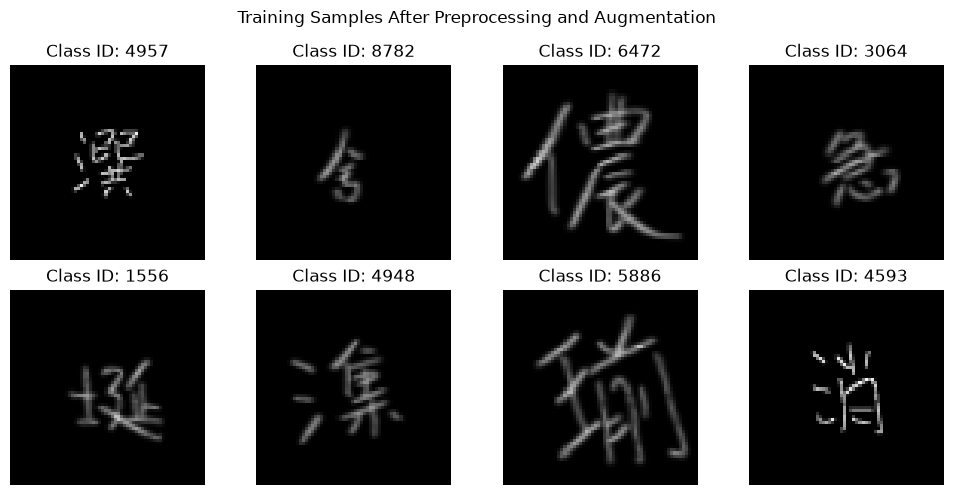

In [8]:
# Step 8 — Verify one batch and save a sample training-image preview
batch_images, batch_labels = next(iter(train_ds.take(1)))
assert tuple(batch_images.shape[1:]) == (IMG_SIZE, IMG_SIZE, 1)
assert float(tf.reduce_min(batch_images)) >= 0.0
assert float(tf.reduce_max(batch_images)) <= 1.0
assert int(tf.reduce_min(batch_labels)) >= 0
assert int(tf.reduce_max(batch_labels)) < NUM_CLASSES

print("Image batch shape:", batch_images.shape)
print("Label batch shape:", batch_labels.shape)
print("Batch pixel range:", float(tf.reduce_min(batch_images)), float(tf.reduce_max(batch_images)))

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(batch_images[i, :, :, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Class ID: {int(batch_labels[i])}")
    ax.axis("off")
plt.suptitle("Training Samples After Preprocessing and Augmentation")
plt.tight_layout()
plt.savefig(RESULT_DIR / "training_samples_preview.png", dpi=150, bbox_inches="tight")
plt.show()


## Part C — Three fixed neural-network architectures

The next three cells **define** the models; training starts in Part D. No extra baseline-optimization stages are required.


In [9]:
# Step 9 — Define Model 1: MLP (fully connected neural network)
L = tf.keras.layers

def make_mlp():
    return tf.keras.Sequential([
        L.Input((IMG_SIZE, IMG_SIZE, 1)),
        L.Flatten(),
        L.Dense(512, activation="relu"),
        L.Dropout(0.30),
        L.Dense(256, activation="relu"),
        L.Dense(NUM_CLASSES, activation="softmax"),
    ], name="MLP")

print("MLP:", make_mlp().count_params(), "parameters")


MLP: 5586697 parameters


In [19]:
# Step 10 — Define Model 2: Basic CNN (three convolution blocks)
def make_basic_cnn():
    return tf.keras.Sequential([
        L.Input((IMG_SIZE, IMG_SIZE, 1)),
        L.Conv2D(32, 3, padding="same", activation="relu"), L.MaxPooling2D(),
        L.Conv2D(64, 3, padding="same", activation="relu"), L.MaxPooling2D(),
        L.Conv2D(128, 3, padding="same", activation="relu"), L.MaxPooling2D(),
        L.Flatten(), L.Dense(256),
        L.LeakyReLU(negative_slope=0.1),
        L.Dense(NUM_CLASSES, activation="softmax"),
    ], name="Basic_CNN")

print("Basic CNN:", make_basic_cnn().count_params(), "parameters")


Basic CNN: 5547785 parameters


In [25]:
# Step 11 — Define Model 3: Deep CNN (deeper convolutional network with BN)
def make_deep_cnn():
    return tf.keras.Sequential([
        L.Input((IMG_SIZE, IMG_SIZE, 1)),
        L.Conv2D(32, 3, padding="same", use_bias=False), L.BatchNormalization(), L.ReLU(),
        L.Conv2D(32, 3, padding="same", use_bias=False), L.BatchNormalization(), L.ReLU(),
        L.MaxPooling2D(),
        L.Conv2D(64, 3, padding="same", use_bias=False), L.BatchNormalization(), L.ReLU(),
        L.Conv2D(64, 3, padding="same", use_bias=False), L.BatchNormalization(), L.ReLU(),
        L.MaxPooling2D(),
        L.Conv2D(128, 3, padding="same", use_bias=False), L.BatchNormalization(), L.ReLU(),
        L.Conv2D(128, 3, padding="same", use_bias=False), L.BatchNormalization(), L.ReLU(),
        L.MaxPooling2D(),
        L.Conv2D(256, 3, padding="same"),
        L.LeakyReLU(negative_slope=0.1),
        L.AveragePooling2D(pool_size=2),
        L.Flatten(),
        L.Dense(256),
        L.LeakyReLU(negative_slope=0.1),
        L.Dropout(0.35),
        L.Dense(NUM_CLASSES, activation="softmax"),
    ], name="Deep_CNN")

print("Deep CNN:", make_deep_cnn().count_params(), "parameters")
assert all(builder().output_shape[-1] == NUM_CLASSES for builder in
           (make_mlp, make_basic_cnn, make_deep_cnn))
print("All models have 13,065 output neurons.")


Deep CNN: 4989481 parameters
All models have 13,065 output neurons.


## Part D — Train the three models

**Training Steps are visible:** each `.fit()` call uses `verbose=1` with a live batch-progress bar. The models have their own code cells so you can run them sequentially. Each successful training run is saved as a `.keras` model and a history CSV. Backups allow recovery from completed epochs after interruptions (but not an unfinished batch).

**The test set is not used while training.** All three architectures and the epoch budget are defined in advance.


In [13]:
# Step 12 — Shared training function and checkpoints
def train_model(model_name, builder):
    done_file = RESULT_DIR / f"{model_name}.done"
    model_file = MODEL_DIR / f"{model_name}_best.keras"
    history_file = RESULT_DIR / f"{model_name}_history.csv"
    backup_folder = BACKUP_DIR / model_name

    if done_file.exists() and model_file.exists() and history_file.exists():
        print(f"{model_name} has already completed; skipping training.")
        return

    # A previous run may have saved an epoch backup. Without a backup,
    # start a fresh CSV history rather than appending to an unrelated run.
    has_backup = backup_folder.is_dir() and any(backup_folder.iterdir())
    if not has_backup and history_file.exists():
        history_file.unlink()

    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(SEED)
    model = builder()
    assert model.output_shape[-1] == NUM_CLASSES
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=INITIAL_LEARNING_RATE,
            global_clipnorm=1.0,
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    callbacks = [
        # Reduce the learning rate if training loss stops improving.
        # The test dataset is never used for learning-rate decisions.
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="loss", mode="min", factor=0.5,
            patience=2, min_lr=MIN_LEARNING_RATE, verbose=1,
        ),
        tf.keras.callbacks.BackupAndRestore(
            backup_dir=str(backup_folder), save_freq="epoch"
        ),
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(model_file), monitor="loss", mode="min",
            save_best_only=True, verbose=0
        ),
        tf.keras.callbacks.CSVLogger(str(history_file), append=has_backup),
    ]
    print(f"\n========== TRAINING {model_name} | {EPOCHS} EPOCHS ==========")
    print(f"Parameters: {model.count_params():,}; batch size: {BATCH_SIZE}; initial LR: {INITIAL_LEARNING_RATE}")
    model.fit(train_ds, epochs=EPOCHS, callbacks=callbacks, verbose=1)
    done_file.write_text(f"Completed {EPOCHS} epochs\n", encoding="utf-8")
    print(f"Completed: {model_name}. Saved model: {model_file}")
    del model
    tf.keras.backend.clear_session()
    gc.collect()

print("Training function configured. Run Steps 13, 14 and 15 in order.")


Training function configured. Run Steps 13, 14 and 15 in order.


In [14]:
# Step 13 — Train Model 1: MLP (live training-step progress)
train_model("MLP_v4", make_mlp)



========== TRAINING MLP_v4 | 8 EPOCHS ==========
Parameters: 5,586,697; batch size: 32; initial LR: 0.0003
Epoch 1/8


/home/lauti/DIT5411/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
2026-11-19 03:21:25.115138: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-11-19 03:21:25.115203: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-11-19 03:21:2

81657/81657 ━━━━━━━━━━━━━━━━━━━━ 459s 6ms/step - accuracy: 0.0463 - loss: 6.5911 - learning_rate: 3.0000e-04
Epoch 2/8
81657/81657 ━━━━━━━━━━━━━━━━━━━━ 449s 6ms/step - accuracy: 0.1721 - loss: 4.5007 - learning_rate: 3.0000e-04
Epoch 3/8
81657/81657 ━━━━━━━━━━━━━━━━━━━━ 448s 5ms/step - accuracy: 0.2581 - loss: 3.7772 - learning_rate: 3.0000e-04
Epoch 4/8
81657/81657 ━━━━━━━━━━━━━━━━━━━━ 441s 5ms/step - accuracy: 0.3113 - loss: 3.4051 - learning_rate: 3.0000e-04
Epoch 5/8
81657/81657 ━━━━━━━━━━━━━━━━━━━━ 434s 5ms/step - accuracy: 0.3476 - loss: 3.1696 - learning_rate: 3.0000e-04
Epoch 6/8
81657/81657 ━━━━━━━━━━━━━━━━━━━━ 435s 5ms/step - accuracy: 0.3725 - loss: 3.0150 - learning_rate: 3.0000e-04
Epoch 7/8
81657/81657 ━━━━━━━━━━━━━━━━━━━━ 439s 5ms/step - accuracy: 0.3911 - loss: 2.9063 - learning_rate: 3.0000e-04
Epoch 8/8
81657/81657 ━━━━━━━━━━━━━━━━━━━━ 433s 5ms/step - accuracy: 0.4041 - loss: 2.8289 - learning_rate: 3.0000e-04
Completed: MLP_v4. Saved model: /home/lauti/DIT5411/result

In [21]:
# Step 14 — Train Model 2: Basic CNN (live training-step progress)
train_model("Basic_CNN_v5", make_basic_cnn)



========== TRAINING Basic_CNN_v5 | 8 EPOCHS ==========
Parameters: 5,547,785; batch size: 32; initial LR: 0.0003
Epoch 1/8
81657/81657 ━━━━━━━━━━━━━━━━━━━━ 497s 6ms/step - accuracy: 0.5679 - loss: 2.6529 - learning_rate: 3.0000e-04
Epoch 2/8
81657/81657 ━━━━━━━━━━━━━━━━━━━━ 486s 6ms/step - accuracy: 0.9130 - loss: 0.3003 - learning_rate: 3.0000e-04
Epoch 3/8
81657/81657 ━━━━━━━━━━━━━━━━━━━━ 484s 6ms/step - accuracy: 0.9455 - loss: 0.1847 - learning_rate: 3.0000e-04
Epoch 4/8
81657/81657 ━━━━━━━━━━━━━━━━━━━━ 463s 6ms/step - accuracy: 0.9583 - loss: 0.1426 - learning_rate: 3.0000e-04
Epoch 5/8
81657/81657 ━━━━━━━━━━━━━━━━━━━━ 463s 6ms/step - accuracy: 0.9657 - loss: 0.1201 - learning_rate: 3.0000e-04
Epoch 6/8
81657/81657 ━━━━━━━━━━━━━━━━━━━━ 469s 6ms/step - accuracy: 0.9698 - loss: 0.1074 - learning_rate: 3.0000e-04
Epoch 7/8
81657/81657 ━━━━━━━━━━━━━━━━━━━━ 468s 6ms/step - accuracy: 0.9729 - loss: 0.0991 - learning_rate: 3.0000e-04
Epoch 8/8
81657/81657 ━━━━━━━━━━━━━━━━━━━━ 466s 6ms/s

In [27]:
# Step 15 — Train Model 3: Deep CNN (live training-step progress)
train_model("Deep_CNN_v6", make_deep_cnn)



========== TRAINING Deep_CNN_v6 | 8 EPOCHS ==========
Parameters: 4,989,481; batch size: 32; initial LR: 0.0003
Epoch 1/8
81657/81657 ━━━━━━━━━━━━━━━━━━━━ 603s 7ms/step - accuracy: 0.6362 - loss: 2.1776 - learning_rate: 3.0000e-04
Epoch 2/8
81657/81657 ━━━━━━━━━━━━━━━━━━━━ 594s 7ms/step - accuracy: 0.9199 - loss: 0.2974 - learning_rate: 3.0000e-04
Epoch 3/8
81657/81657 ━━━━━━━━━━━━━━━━━━━━ 582s 7ms/step - accuracy: 0.9409 - loss: 0.2225 - learning_rate: 3.0000e-04
Epoch 4/8
81657/81657 ━━━━━━━━━━━━━━━━━━━━ 581s 7ms/step - accuracy: 0.9504 - loss: 0.1884 - learning_rate: 3.0000e-04
Epoch 5/8
81657/81657 ━━━━━━━━━━━━━━━━━━━━ 601s 7ms/step - accuracy: 0.9558 - loss: 0.1688 - learning_rate: 3.0000e-04
Epoch 6/8
81657/81657 ━━━━━━━━━━━━━━━━━━━━ 595s 7ms/step - accuracy: 0.9599 - loss: 0.1550 - learning_rate: 3.0000e-04
Epoch 7/8
81657/81657 ━━━━━━━━━━━━━━━━━━━━ 600s 7ms/step - accuracy: 0.9628 - loss: 0.1447 - learning_rate: 3.0000e-04
Epoch 8/8
81657/81657 ━━━━━━━━━━━━━━━━━━━━ 602s 7ms/st

## Part E — Final testing and English report results

Only execute the following cells **after all three models have completed training**. Each saved model is evaluated on the same untouched test set. Do not modify architectures or training settings based on these final results.


In [29]:
# Step 16 — Evaluate all three completed models on the test dataset
model_names = ["MLP_v4", "Basic_CNN_v5", "Deep_CNN_v6"]
for name in model_names:
    assert (RESULT_DIR / f"{name}.done").exists(), f"Finish training {name} first."
    assert (MODEL_DIR / f"{name}_best.keras").exists()
    assert (RESULT_DIR / f"{name}_history.csv").exists()

comparison_rows = []
training_histories = {}
for name in model_names:
    history = pd.read_csv(RESULT_DIR / f"{name}_history.csv")
    training_histories[name] = history
    model = tf.keras.models.load_model(MODEL_DIR / f"{name}_best.keras")
    print(f"\n========== TESTING {name} ==========")
    test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
    best_training_row = history.loc[history["loss"].idxmin()]
    comparison_rows.append({
        "Model": name,
        "Epochs": EPOCHS,
        "Parameters": model.count_params(),
        "Training Accuracy": float(best_training_row["accuracy"]),
        "Training Loss": float(best_training_row["loss"]),
        "Test Accuracy": float(test_accuracy),
        "Test Loss": float(test_loss),
    })
    del model
    tf.keras.backend.clear_session()
    gc.collect()

comparison = pd.DataFrame(comparison_rows).sort_values(
    "Test Accuracy", ascending=False
).reset_index(drop=True)
comparison.to_csv(RESULT_DIR / "model_comparison.csv", index=False)
display(comparison)
print("Best measured test accuracy:", comparison.iloc[0]["Model"])



========== TESTING MLP_v4 ==========
5069/5080 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5445 - loss: 1.9936

2026-11-19 19:52:49.395217: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_29', 8 bytes spill stores, 8 bytes spill loads

2026-11-19 19:52:49.493362: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_29', 52 bytes spill stores, 52 bytes spill loads

2026-11-19 19:52:49.540771: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_43', 32 bytes spill stores, 32 bytes spill loads



5080/5080 ━━━━━━━━━━━━━━━━━━━━ 23s 4ms/step - accuracy: 0.5441 - loss: 1.9959

========== TESTING Basic_CNN_v5 ==========
5079/5080 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9227 - loss: 0.6051

2026-11-19 19:53:12.666015: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_74', 8 bytes spill stores, 8 bytes spill loads



5080/5080 ━━━━━━━━━━━━━━━━━━━━ 22s 4ms/step - accuracy: 0.9226 - loss: 0.6053

========== TESTING Deep_CNN_v6 ==========
5071/5080 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9825 - loss: 0.0932

2026-11-19 19:53:37.084297: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_227', 8 bytes spill stores, 8 bytes spill loads



5080/5080 ━━━━━━━━━━━━━━━━━━━━ 24s 4ms/step - accuracy: 0.9825 - loss: 0.0931


,Model,Epochs,Parameters,Training Accuracy,Training Loss,Test Accuracy,Test Loss
0,Deep_CNN_v6,8,4989481,0.965207,0.136405,0.982467,0.093104
1,Basic_CNN_v5,8,5547785,0.975268,0.092294,0.922639,0.605271
2,MLP_v4,8,5586697,0.404108,2.828911,0.544122,1.995948


Best measured test accuracy: Deep_CNN_v6


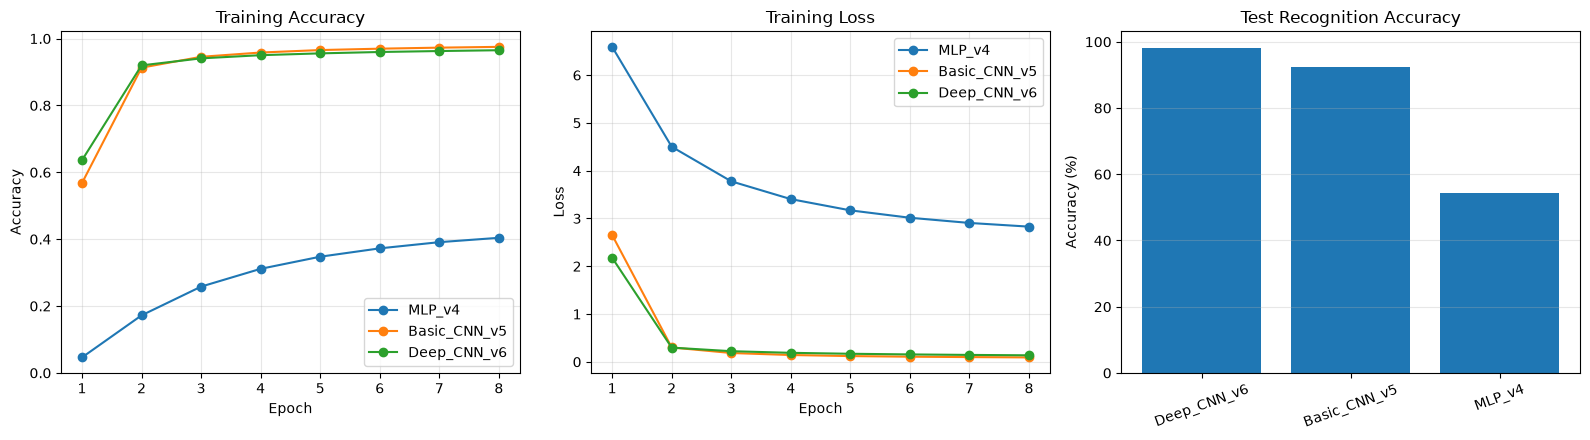

Chart saved to: /home/lauti/DIT5411/results_diagnostic_v4/model_comparison.png


In [32]:
# Step 17 — Plot training curves and compare testing recognition accuracy
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for name, history in training_histories.items():
    axes[0].plot(history["epoch"] + 1, history["accuracy"], marker="o", label=name)
    axes[1].plot(history["epoch"] + 1, history["loss"], marker="o", label=name)
axes[0].set(title="Training Accuracy", xlabel="Epoch", ylabel="Accuracy")
axes[1].set(title="Training Loss", xlabel="Epoch", ylabel="Loss")
for axis in axes[:2]:
    axis.legend()
    axis.grid(True, alpha=0.3)
axes[2].bar(comparison["Model"], comparison["Test Accuracy"] * 100)
axes[2].set(title="Test Recognition Accuracy", ylabel="Accuracy (%)")
axes[2].tick_params(axis="x", rotation=20)
axes[2].grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(RESULT_DIR / "model_comparison.png", dpi=160, bbox_inches="tight")
plt.show()
print("Chart saved to:", RESULT_DIR / "model_comparison.png")


In [33]:
# Step 18 — Export a ready-to-paste English results table for README.md
report_lines = [
    "## Experimental Results",
    "",
    "The MLP, Basic CNN, and Deep CNN architectures were trained using the same",
    "13,065-class dataset and 200 planned training samples per class per epoch.",
    "The original testing images were reserved for final recognition evaluation.",
    "",
    "| Model | Epochs | Parameters | Training accuracy | Test accuracy | Test loss |",
    "|---|---:|---:|---:|---:|---:|",
]
for _, result in comparison.iterrows():
    report_lines.append(
        f'| {result["Model"]} | {int(result["Epochs"])} | '
        f'{int(result["Parameters"]):,} | {result["Training Accuracy"]:.2%} | '
        f'{result["Test Accuracy"]:.2%} | {result["Test Loss"]:.4f} |'
    )
report_lines.extend([
    "",
    f'**Highest testing accuracy:** {comparison.iloc[0]["Model"]} '
    f'({comparison.iloc[0]["Test Accuracy"]:.2%}).',
    "",
    "![Training curves and test accuracy](results_diagnostic_v4/model_comparison.png)",
])
report_path = RESULT_DIR / "RESULTS_FOR_README.md"
report_path.write_text("\n".join(report_lines) + "\n", encoding="utf-8")
print("English README results written to:", report_path)


English README results written to: /home/lauti/DIT5411/results_diagnostic_v4/RESULTS_FOR_README.md
